# 01 — Exploratory Data Analysis

DeepWeeds: 17,509 RGB field images, 8 weed species + Negative.

1. Integrity checks
2. Class distribution
3. Image properties (resolution / format)
4. Example images per class
5. Colour statistics per class
6. Capture date / time — proxy for site, and capture-session near-duplicates (leakage risk)
7. Pixel-space separability (PCA / t-SNE preview for the classical baseline)

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

ROOT = Path('..')
DATA = ROOT / 'data'
IMG_DIR = DATA / 'images'
FIG_DIR = ROOT / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
RNG = np.random.default_rng(42)

labels = pd.read_csv(DATA / 'labels.csv')
labels.head()

,Filename,Label,Species
0,20160928-140314-0.jpg,0,Chinee apple
1,20160928-140337-0.jpg,0,Chinee apple
2,20160928-140731-0.jpg,0,Chinee apple
3,20160928-140747-0.jpg,0,Chinee apple
4,20160928-141107-0.jpg,0,Chinee apple


## 1. Integrity checks

In [2]:
print('rows:', len(labels))
print('missing values:', labels.isna().sum().sum())
print('duplicate filenames:', labels.Filename.duplicated().sum())
on_disk = {p.name for p in IMG_DIR.glob('*.jpg')}
print('images on disk:', len(on_disk))
print('labelled but missing on disk:', len(set(labels.Filename) - on_disk))
print('on disk but unlabelled:', len(on_disk - set(labels.Filename)))
print('label <-> species mapping is 1:1:', labels.groupby('Label').Species.nunique().eq(1).all())
labels.groupby(['Label', 'Species']).size().rename('count').reset_index()

rows: 17509
missing values: 0
duplicate filenames: 0
images on disk: 17509
labelled but missing on disk: 0
on disk but unlabelled: 0
label <-> species mapping is 1:1: True


,Label,Species,count
0,0,Chinee apple,1125
1,1,Lantana,1064
2,2,Parkinsonia,1031
3,3,Parthenium,1022
4,4,Prickly acacia,1062
5,5,Rubber vine,1009
6,6,Siam weed,1074
7,7,Snake weed,1016
8,8,Negative,9106


## 2. Class distribution

Negative share: 52.0%
Weed classes range 1009–1125 (imbalance ratio among weeds 1.11)
Majority-class (Negative) accuracy baseline: 52.0%


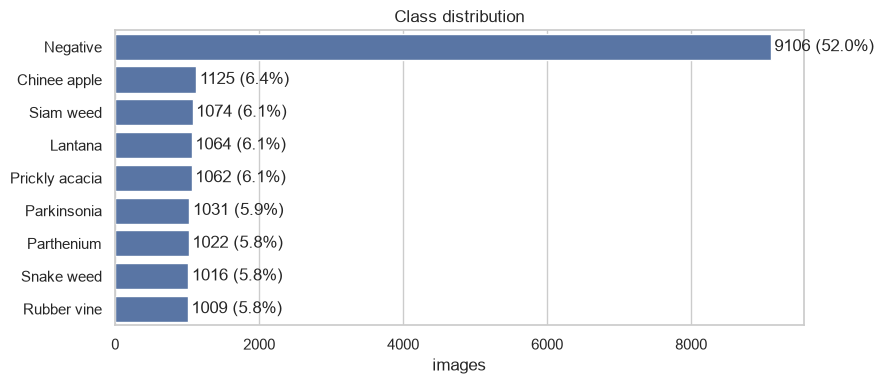

In [3]:
counts = labels.Species.value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=counts.values, y=counts.index, ax=ax, color='C0')
for i, v in enumerate(counts.values):
    ax.text(v + 50, i, f'{v} ({v / len(labels):.1%})', va='center')
ax.set_xlabel('images'); ax.set_ylabel('')
ax.set_title('Class distribution')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_class_distribution.png', dpi=150)

weeds = counts.drop('Negative')
print(f'Negative share: {counts["Negative"] / len(labels):.1%}')
print(f'Weed classes range {weeds.min()}–{weeds.max()} (imbalance ratio among weeds {weeds.max() / weeds.min():.2f})')
print(f'Majority-class (Negative) accuracy baseline: {counts.max() / len(labels):.1%}')

**Takeaway:** the 8 weed classes are nearly balanced (~1,000 each), but *Negative* is ~52% of the data.
A majority-class predictor already scores ~52% accuracy, so **accuracy is misleading — report macro-F1** (as planned in `src/evaluation/metrics.py`) and consider class weights / resampling.

## 3. Image properties

In [4]:
props = Counter()
for f in labels.Filename:
    with Image.open(IMG_DIR / f) as im:
        props[(im.size, im.mode, im.format)] += 1
props

Counter({((256, 256), 'RGB', 'JPEG'): 17509})

All images are **256×256 RGB JPEG** — no resizing or channel handling edge cases.
Transfer-learning backbones expect 224×224, so a random/center crop is a natural fit.

## 4. Example images per class

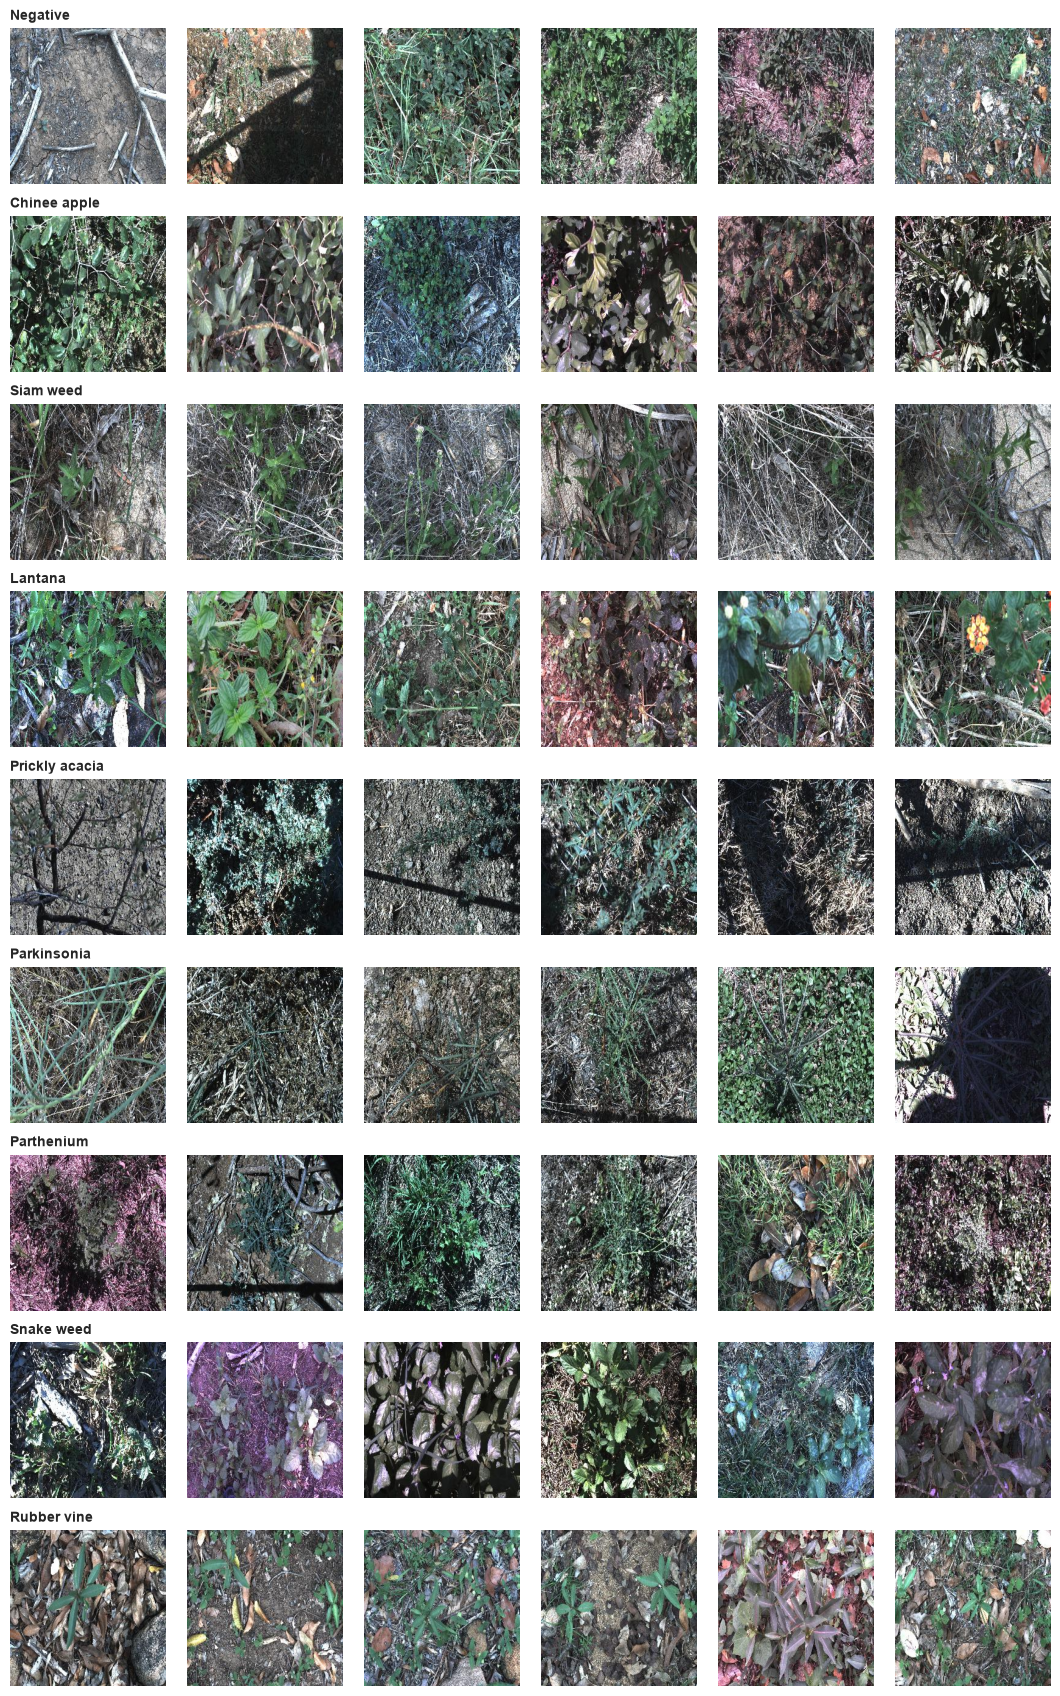

In [5]:
classes = counts.index.tolist()
n = 6
fig, axes = plt.subplots(len(classes), n, figsize=(n * 1.8, len(classes) * 1.9))
for r, cls in enumerate(classes):
    sample = labels[labels.Species == cls].sample(n, random_state=42)
    for c, f in enumerate(sample.Filename):
        ax = axes[r, c]
        ax.imshow(Image.open(IMG_DIR / f)); ax.axis('off')
        if c == 0:
            ax.set_title(cls, loc='left', fontsize=10, fontweight='bold')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_samples_per_class.png', dpi=120)

Images are cluttered in-situ scenes: weeds are often small, partially occluded, and share background (grass, soil, other vegetation) with *Negative* images. Lighting varies a lot (shadows, overexposure). Expect classical pixel/histogram features to struggle.

## 5. Colour statistics per class

In [6]:
def colour_stats(path):
    a = np.asarray(Image.open(path), dtype=np.float32) / 255
    hsv = np.asarray(Image.open(path).convert('HSV'), dtype=np.float32) / 255
    return [*a.mean((0, 1)), a.std(), hsv[..., 1].mean(), hsv[..., 2].mean()]

sub = labels.groupby('Species').sample(400, random_state=42)
stats = pd.DataFrame([colour_stats(IMG_DIR / f) for f in sub.Filename],
                     columns=['R', 'G', 'B', 'contrast', 'saturation', 'brightness'], index=sub.index)
stats['Species'] = sub.Species
stats.groupby('Species').mean().round(3).sort_values('G')

,R,G,B,contrast,saturation,brightness
Species,,,,,,
Prickly acacia,0.324,0.342,0.343,0.256,0.175,0.357
Snake weed,0.344,0.345,0.343,0.233,0.194,0.374
Chinee apple,0.338,0.347,0.333,0.241,0.204,0.370
Parthenium,0.340,0.350,0.350,0.247,0.229,0.379
Parkinsonia,0.349,0.367,0.354,0.237,0.168,0.379
Rubber vine,0.381,0.401,0.388,0.223,0.194,0.428
Lantana,0.352,0.402,0.365,0.224,0.232,0.419
Negative,0.403,0.403,0.396,0.220,0.184,0.437
Siam weed,0.409,0.438,0.405,0.206,0.171,0.456


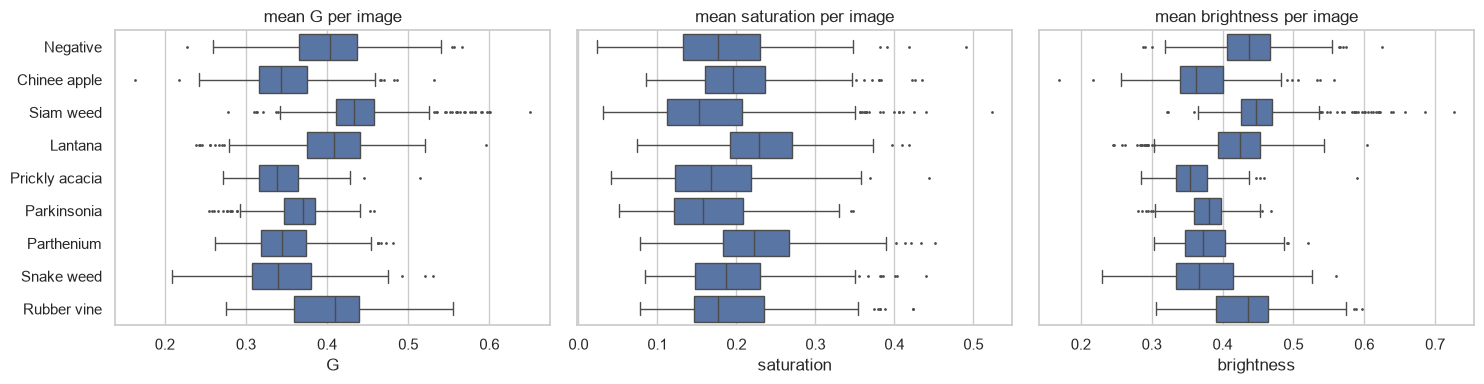

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ['G', 'saturation', 'brightness']):
    sns.boxplot(data=stats, x=col, y='Species', order=classes, ax=ax, fliersize=1)
    ax.set_title(f'mean {col} per image'); ax.set_ylabel('')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_colour_stats.png', dpi=150)

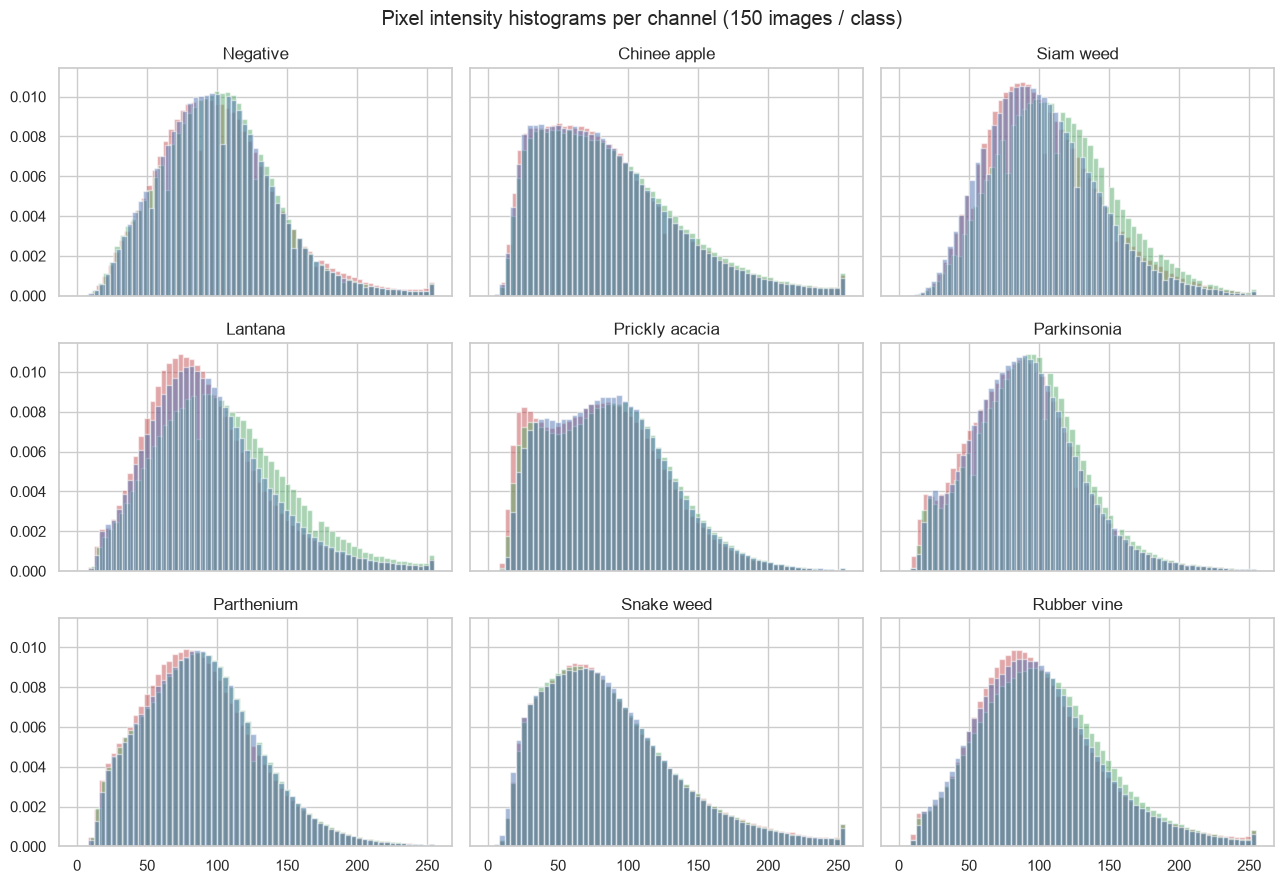

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True, sharey=True)
for ax, cls in zip(axes.flat, classes):
    fs = labels[labels.Species == cls].sample(150, random_state=0).Filename
    arr = np.stack([np.asarray(Image.open(IMG_DIR / f).resize((64, 64))) for f in fs])
    for i, ch in enumerate('rgb'):
        ax.hist(arr[..., i].ravel(), bins=64, color=ch, alpha=0.5, density=True)
    ax.set_title(cls)
fig.suptitle('Pixel intensity histograms per channel (150 images / class)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_rgb_histograms.png', dpi=120)

Per-channel histograms overlap heavily, so colour alone can't separate species. Global **brightness** does shift between classes, though: Siam weed, Negative, Rubber vine and Lantana are clearly brighter than Prickly acacia, Parkinsonia and Chinee apple. That gap reflects *where and when* each class was photographed (site, time of day, canopy shade) more than the plant itself. A colour-histogram KNN will partly exploit this shortcut. It should beat chance, but some of its accuracy will come from lighting rather than the weed.

## 6. Capture date / time

`labels.csv` has **no site column**. Filenames follow `YYYYMMDD-HHMMSS-N`, so the capture date is the best available proxy for site
(each collection trip visited one location). 

In [9]:
parts = labels.Filename.str.extract(r'(?P<date>\d{8})-(?P<time>\d{6})-(?P<idx>\d+)\.jpg')
labels['date'] = pd.to_datetime(parts.date, format='%Y%m%d')
labels['timestamp'] = pd.to_datetime(parts.date + parts.time, format='%Y%m%d%H%M%S')
labels['burst_idx'] = parts.idx.astype(int)
print('date range:', labels.date.min().date(), '→', labels.date.max().date())
print('distinct capture dates:', labels.date.nunique())

date range: 2016-09-28 → 2018-03-22
distinct capture dates: 60


classes per date:
1    28
2    18
3    11
4     2
5     1
Name: num dates, dtype: int64


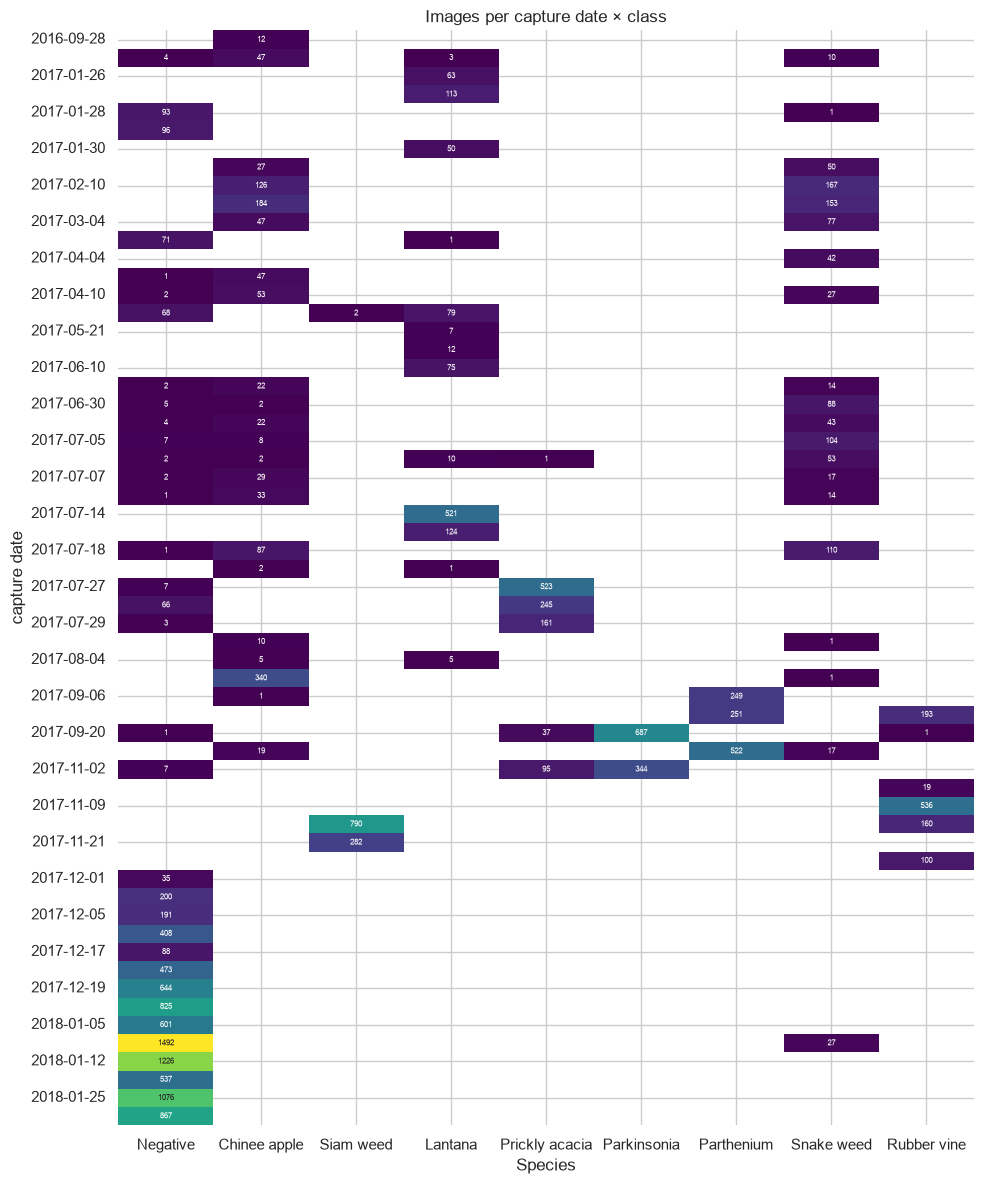

In [10]:
by_date = pd.crosstab(labels.date.dt.strftime('%Y-%m-%d'), labels.Species)[classes]
fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(by_date.replace(0, np.nan), cmap='viridis', annot=True, fmt='.0f', annot_kws={'size': 6}, cbar=False, ax=ax)
ax.set_title('Images per capture date × class'); ax.set_ylabel('capture date')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_date_by_class.png', dpi=130)

print('classes per date:')
print(by_date.gt(0).sum(axis=1).value_counts().sort_index().rename('num dates'))

Most dates contain only 1–2 classes, and each weed class is collected on its own set of dates.
Date (≈ site / weather / lighting) is therefore **strongly confounded with class** — a model can partly learn the *location* rather than the plant.
This motivates the leave-one-site-out evaluation; with no site column, **grouping by date** is a workable substitute.

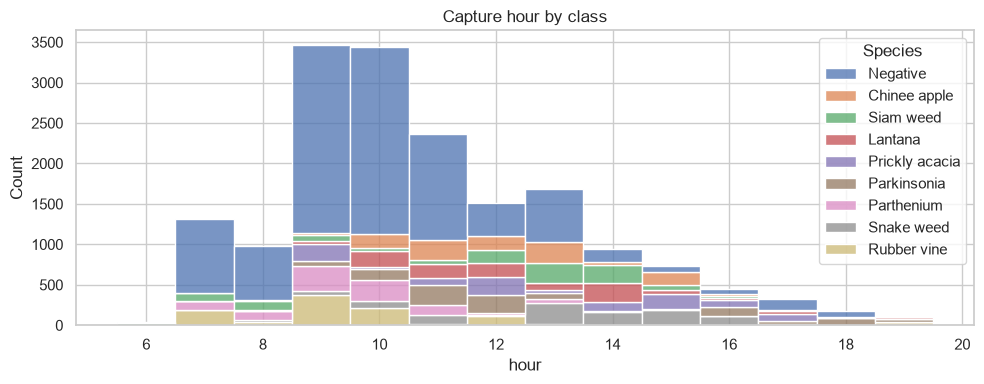

In [11]:
labels['hour'] = labels.timestamp.dt.hour
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=labels, x='hour', hue='Species', hue_order=classes, multiple='stack', discrete=True, ax=ax)
ax.set_title('Capture hour by class')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_capture_hour.png', dpi=150)

### Filename suffix `-N`

Only ~300 timestamps share more than one frame, so `-N` is not a burst index. It takes values 0–4 and 1–3 values appear per date — most likely a camera / instrument ID. Cross-tab with class:

In [12]:
labels['suffix'] = labels.burst_idx
pd.crosstab(labels.suffix, labels.Species)[classes]

Species,Negative,Chinee apple,Siam weed,Lantana,Prickly acacia,Parkinsonia,Parthenium,Snake weed,Rubber vine
suffix,,,,,,,,,
0,358,661,130,403,1,0,0,860,0
1,2627,200,469,311,518,350,464,2,482
2,4457,263,193,177,233,330,396,139,166
3,1664,0,282,173,310,351,136,15,361
4,0,1,0,0,0,0,26,0,0


### Capture sessions (train/test leakage risk)

Images were taken as the camera moved through a field. Consecutive shots seconds apart show overlapping ground — near-duplicates.
We define a **session** as a run of images with < 60 s between consecutive captures.

Frames in a session are **not pixel-level duplicates**, since each shot shows different ground (see the similarity check below). They do share the same site, soil, lighting and even the photographer's shadow. That shared context is what a model could memorise.

count      17508.0
mean        2664.8
std        81692.0
min            0.0
25%            6.0
50%           11.0
75%           20.0
max      6036380.0
Name: timestamp, dtype: float64
share of consecutive gaps ≤10s: 48.3%, ≤60s: 94.9%
sessions: 892
session size:
count    892.0
mean      19.6
std       49.3
min        1.0
25%        1.0
50%        3.0
75%       11.2
max      365.0
Name: size, dtype: float64
sessions containing >1 class: 89


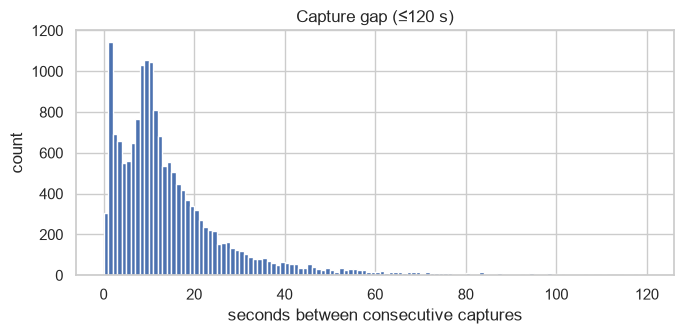

In [13]:
ordered = labels.sort_values('timestamp')
gap = ordered.timestamp.diff().dt.total_seconds()
print(gap.describe().round(1))
print(f'share of consecutive gaps ≤10s: {(gap <= 10).mean():.1%}, ≤60s: {(gap <= 60).mean():.1%}')

labels['session'] = (gap.gt(60) | gap.isna()).cumsum().reindex(labels.index)
sess = labels.groupby('session').agg(size=('Filename', 'size'), n_classes=('Species', 'nunique'))
print('sessions:', len(sess))
print('session size:'); print(sess['size'].describe().round(1))
print('sessions containing >1 class:', (sess.n_classes > 1).sum())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(gap[gap <= 120], bins=120)
ax.set_xlabel('seconds between consecutive captures'); ax.set_ylabel('count')
ax.set_title('Capture gap (≤120 s)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_capture_gaps.png', dpi=150)

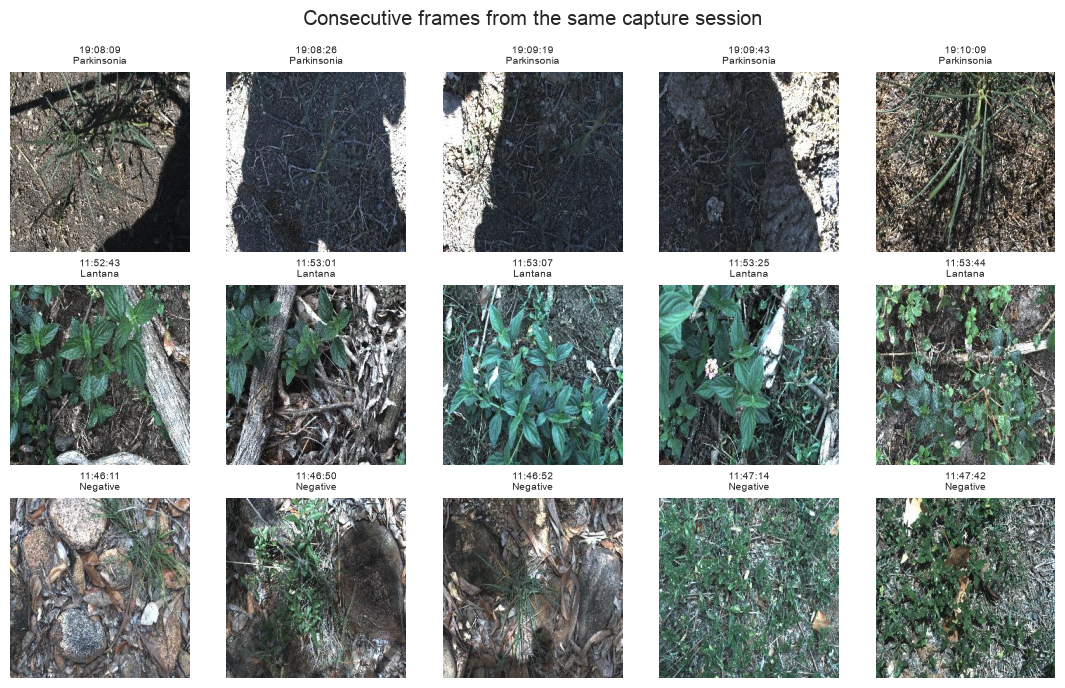

In [14]:
# Consecutive frames of one session
s_id = sess[(sess['size'] >= 8) & (sess.n_classes == 1)].sample(3, random_state=3).index
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for r, sid in enumerate(s_id):
    rows = labels[labels.session == sid].sort_values('timestamp').head(5)
    for c, (_, row) in enumerate(rows.iterrows()):
        axes[r, c].imshow(Image.open(IMG_DIR / row.Filename)); axes[r, c].axis('off')
        axes[r, c].set_title(f"{row.timestamp:%H:%M:%S}\n{row.Species}", fontsize=7)
fig.suptitle('Consecutive frames from the same capture session')
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_sessions.png', dpi=130)

median sim — consecutive: 0.041, random same-class: 0.006


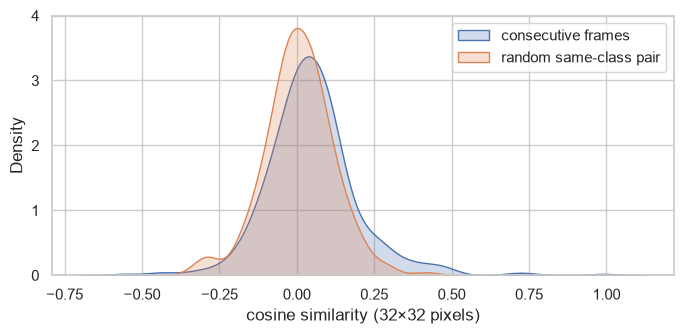

In [15]:
# Are neighbouring frames more similar than random same-class pairs? (cosine sim, 32x32 pixels)
def vec(f):
    v = np.asarray(Image.open(IMG_DIR / f).resize((32, 32)), dtype=np.float32).ravel()
    v -= v.mean(); return v / (np.linalg.norm(v) + 1e-8)

o = labels.sort_values('timestamp').reset_index(drop=True)
idx = RNG.choice(np.where((o.session.values[1:] == o.session.values[:-1]))[0], 400, replace=False)
neigh = [vec(o.Filename[i]) @ vec(o.Filename[i + 1]) for i in idx]
rand = []
for i in idx:
    g = o[o.Species == o.Species[i]].Filename.sample(2, random_state=int(i)).values
    rand.append(vec(g[0]) @ vec(g[1]))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.kdeplot(neigh, label='consecutive frames', fill=True, ax=ax)
sns.kdeplot(rand, label='random same-class pair', fill=True, ax=ax)
ax.set_xlabel('cosine similarity (32×32 pixels)'); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_neighbour_similarity.png', dpi=150)
print(f'median sim — consecutive: {np.median(neigh):.3f}, random same-class: {np.median(rand):.3f}')

## 7. Pixel-space separability

variance explained by 50 PCs: 57.3%


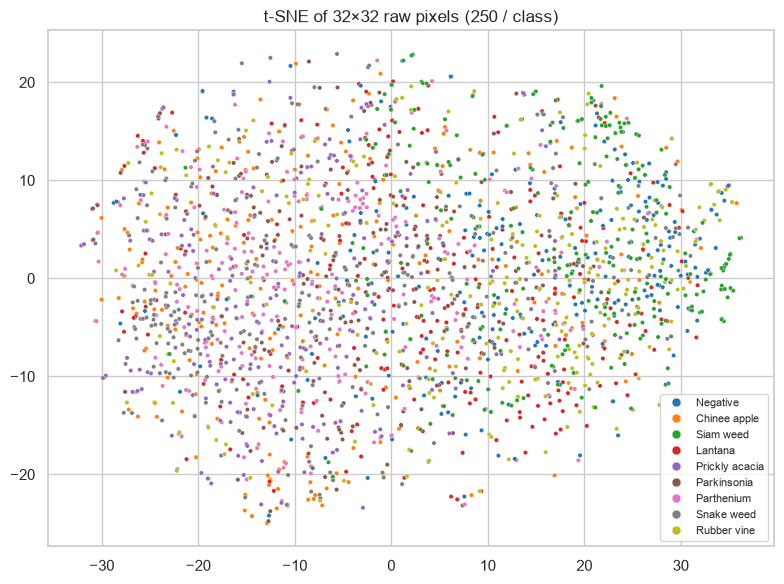

In [16]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sub = labels.groupby('Species').sample(250, random_state=42)
X = np.stack([np.asarray(Image.open(IMG_DIR / f).resize((32, 32)), dtype=np.float32).ravel() / 255 for f in sub.Filename])
Xp = PCA(50, random_state=42).fit(X)
print(f'variance explained by 50 PCs: {Xp.explained_variance_ratio_.sum():.1%}')
emb = TSNE(2, random_state=42, init='pca', perplexity=30).fit_transform(Xp.transform(X))
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=sub.Species.values, hue_order=classes, s=10, ax=ax, palette='tab10')
ax.set_title('t-SNE of 32×32 raw pixels (250 / class)'); ax.legend(fontsize=8, markerscale=2)
fig.tight_layout(); fig.savefig(FIG_DIR / 'eda_tsne_pixels.png', dpi=150)

## Summary & implications

| Finding | Implication |
|---|---|
| All images 256×256 RGB JPEG, no missing/duplicate labels | Minimal cleaning; center/random crop to 224 for pretrained backbones |
| *Negative* ≈ 52% of data; weed classes balanced (~1,000 each) | Use **macro-F1**, not accuracy; majority baseline ≈ 52% acc; consider class weights |
| Heavy colour overlap between classes, but a systematic per-class **brightness shift** | Classical baselines will be weak and partly exploit lighting shortcuts. This motivates CNNs (Q1 → Q2) and brightness/contrast augmentation |
| Raw-pixel t-SNE shows no class clusters, only a broad left→right gradient (Siam weed / Negative on one side) that follows brightness | Raw pixels capture global illumination, not plant shape. Learned features are needed |
| No site column; capture **date strongly confounded with class** | Risk of learning site/lighting instead of plant; group by date as a site proxy for leave-one-site-out |
| Images come in continuous **capture sessions** (median 11 s apart, 892 sessions) that share site, lighting and background, though they aren't pixel duplicates | A random stratified split scatters each session across train and test, so test images come from settings already seen in training. Expect optimistic scores. Report a session- or date-grouped split (`StratifiedGroupKFold`) alongside the random split |
| Wide lighting variation | Brightness/contrast/colour-jitter augmentation is well justified |